In [ ]:
'''
investigate single-row brightening
'''

In [2]:
import numpy as np
import pandas as pd
from astropy.io import fits
import matplotlib.pyplot as plt
import precision_recall as pr
import gc  # garbage collector
import review_findings_functions as rff
import os
import importlib
import implantation_functions as imp
import corner


plt.rcParams["figure.figsize"] = (10, 7)
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gist_gray"

In [ ]:
319001

In [5]:
concat_filtered_with_rf = pd.read_csv('/lustre/lrspec/ZTF_data/science_extractions/1020april26/average/concat_filtered_with_rf') 

In [4]:
concat_filtered_with_rf

,Unnamed: 0.9,Unnamed: 0.8,Unnamed: 0.7,Unnamed: 0.6,Unnamed: 0.5,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,...,height_dimming_f3,FWHM_dimming_f3,signal_local_dimming_f3,central_point_dimming_f3,snr_local,snr_global,real_type_local,real_type_global,distance_from_start,random_forest_result
0,0,0,0,0,0,0,0,0,0,0,...,-356.194423,3.0,30.026146,690.0,0.120616,0.145088,pos,pos,138.500000,0.0
1,1,1,1,1,1,1,1,1,1,3,...,-472.117198,5.0,42.164851,1160.0,0.163725,0.148208,neg,neg,-338.312500,0.0
2,2,2,2,2,2,2,2,2,2,4,...,-117.115640,1.0,10.821998,2070.0,0.507125,0.409946,pos,pos,-1255.173913,0.0
3,3,3,3,3,3,3,3,3,3,6,...,-680.929089,6.0,54.227081,2461.0,0.190395,0.198984,pos,pos,-1632.625000,0.0
4,4,4,4,4,4,4,4,4,4,7,...,-279.760163,1.0,16.726032,2562.0,0.191027,0.187296,neg,neg,-1736.500000,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
347419,347419,347419,347419,347419,347419,347419,347419,347419,49,77,...,-198.335604,2.0,19.493971,833.0,0.377672,0.401030,neg,neg,625.500000,0.0
347420,347420,347420,347420,347420,347420,347420,347420,347420,50,34,...,-89.109350,3.0,13.851402,1253.0,0.918655,0.889413,neg,neg,-388.214286,0.0
347421,347421,347421,347421,347421,347421,347421,347421,347421,51,39,...,-34.856257,1.0,5.903919,1338.0,0.845833,0.911684,pos,pos,-491.156250,0.0
347422,347422,347422,347422,347422,347422,347422,347422,347422,0,0,...,-709.111444,3.0,41.629913,834.0,0.283822,0.246317,pos,pos,1227.142857,0.0


In [8]:
concat_filtered_with_rf.loc[319001]['quad']

3

In [7]:
hdul = fits.open('/lustre/lrspec/ZTF_data/2022/1020/ztf_20221020141806_000686_zi_c13_x_0025.fits.fz')

In [10]:
image = hdul[3].data

In [6]:
df_row = concat_filtered_with_rf.loc[319001]

In [24]:
zoom = image[int(df_row['row_from_nn'])-10:int(df_row['row_from_nn'])+20,int(df_row['col_from_nn'])-10:int(df_row['col_from_nn'])+20]

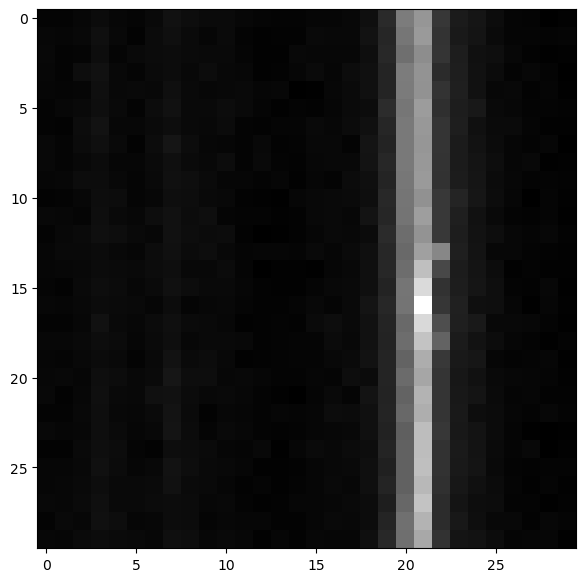

In [25]:
plt.imshow(zoom)

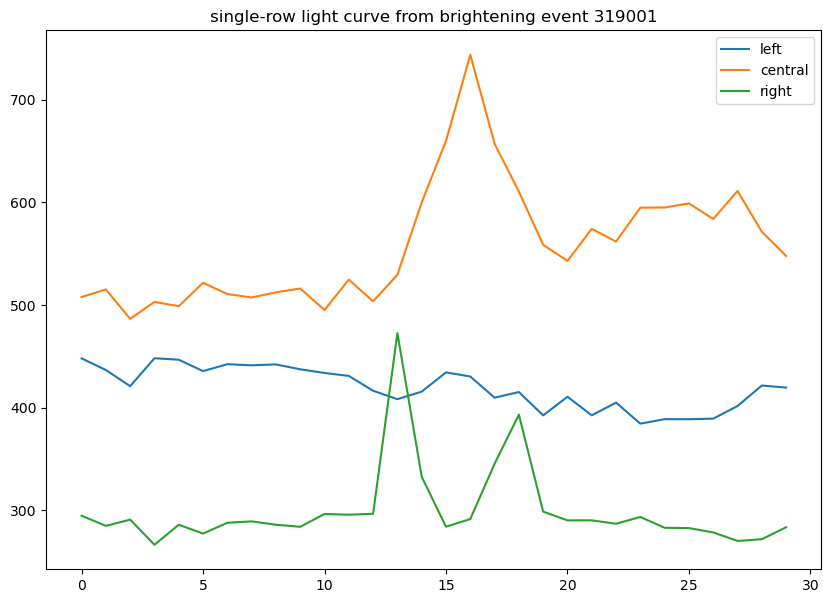

In [27]:
plt.title("single-row light curve from brightening event 319001")
plt.plot(zoom[:,20], label='left')
plt.plot(zoom[:,21], label='central')
plt.plot(zoom[:,22], label='right')
plt.legend()

In [21]:
newbrightening = pd.read_csv('/lustre/lrspec/ZTF_data/newbrightening')

In [29]:
newbrightening.loc[154]

Unnamed: 0.3                                                                         15790
Unnamed: 0.2                                                                         15790
Unnamed: 0.1                                                                             4
Unnamed: 0                                                                               7
filename                                          ztf_20221020157697_000640_zi_c02_x_0004.
quad                                                                                     3
type                                                                                  both
row_from_nn                                                                    1709.407554
col_from_nn                                                                     2770.62209
detection_size                                                                         100
closest_x                                                                           2781.0

In [32]:
index = 154
df_row_2 = newbrightening.loc[154]
hdul = fits.open('/lustre/lrspec/ZTF_data/2022/1020/'+df_row_2['filename']+'fits.fz')
image = hdul[df_row_2['quad']].data

In [33]:
df_row = df_row_2
zoom2 = image[int(df_row['row_from_nn'])-10:int(df_row['row_from_nn'])+20,int(df_row['col_from_nn'])-10:int(df_row['col_from_nn'])+20]

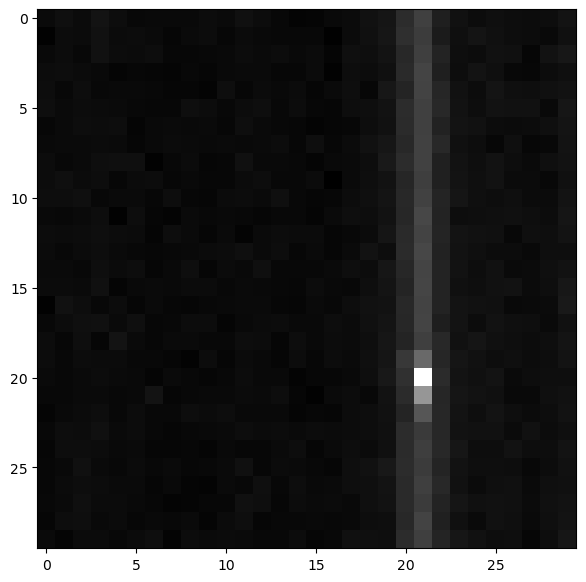

In [37]:
plt.imshow(np.sqrt(zoom2))

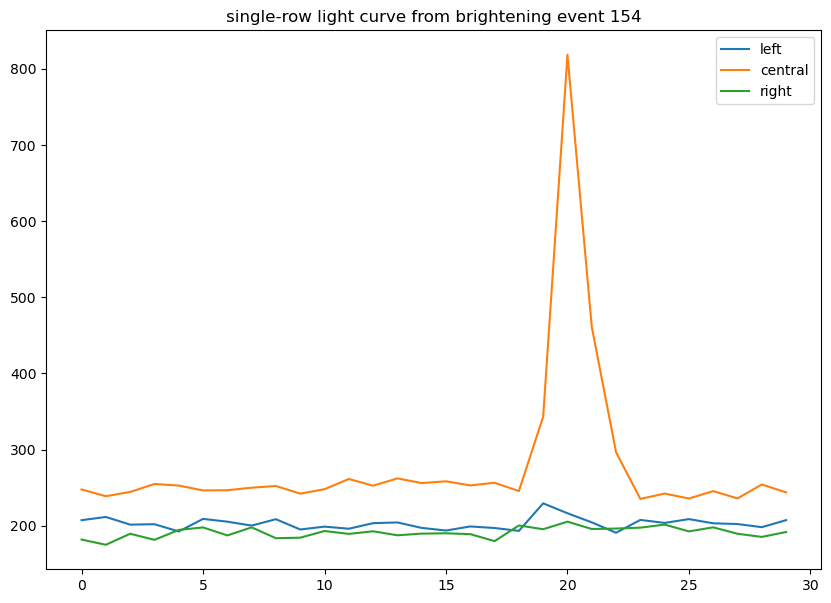

In [36]:
plt.title("single-row light curve from brightening event "+str(index))
plt.plot(zoom2[:,20], label='left')
plt.plot(zoom2[:,21], label='central')
plt.plot(zoom2[:,22], label='right')
plt.legend()

In [3]:
nodupsconcat = pd.read_csv('/home/3155/nodupsconcat_gaia')

In [9]:
concat_filtered_with_rf.loc[319001]

Unnamed: 0.9               319001
Unnamed: 0.8               319001
Unnamed: 0.7               319001
Unnamed: 0.6               319001
Unnamed: 0.5               319001
                          ...    
snr_global               1.029469
real_type_local               pos
real_type_global              pos
distance_from_start    -56.009539
random_forest_result          0.0
Name: 319001, Length: 83, dtype: object

In [ ]:
local_average_outside_brightening                                               192.534491

In [18]:
df_row = concat_filtered_with_rf[concat_filtered_with_rf['local_average_outside_brightening']==192.534491]   

In [20]:
df_row

,Unnamed: 0.9,Unnamed: 0.8,Unnamed: 0.7,Unnamed: 0.6,Unnamed: 0.5,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,...,height_dimming_f3,FWHM_dimming_f3,signal_local_dimming_f3,central_point_dimming_f3,snr_local,snr_global,real_type_local,real_type_global,distance_from_start,random_forest_result


In [ ]:
newbrightening

In [22]:
merged_df = newbrightening.merge(
    nodupsconcat[['filename', 'quad', 'closest_x', 'star_ra', 'star_dec', 'gaia_source_id',
       'ztf_g_gaia_bp_rp_mag', 'ztf_ri_gaia_rp_mag', 'variability',
       'in_vari_summary']],
    on=['filename', 'quad', 'closest_x'],
    how='left'
)

In [23]:
newbrightening

,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,quad,type,row_from_nn,col_from_nn,detection_size,...,local_average_outside_dimming,height_dimming,FWHM_dimming,signal_local_dimming,central_point_dimming,quadrant,num_in_file_in_star,sobel_ratiocentral_point_brightening5,sobels_xcentral_point_brightening5,sobels_ycentral_point_brightening5
0,51,51,5,10,ztf_20221020154120_000640_zi_c11_x_0012.,4,both,1511.922323,815.613122,53,...,344.338891,-23.678064,1.0,4.866011,1538.0,4,1.0,1.027751,[[ 3.54990692e+01 7.03724670e+00 4.80153656e...,[[ 7.6030121e+00 -1.7277786e+01 -3.3199966e+01...
1,120,120,2,8,ztf_20221020163819_000640_zg_c10_x_0003.,3,both,465.183062,515.017927,74,...,325.550361,-25.022224,2.0,7.062065,491.0,3,1.0,0.656194,[[ 23.885605 14.508545 69.82497 232....,[[ 1.55741425e+01 1.74670105e+01 2.51551361e...
2,252,252,1,5,ztf_20221020157697_000640_zi_c12_x_0000.,1,both,2562.299905,877.769116,106,...,382.675806,-50.547938,1.0,7.109707,2563.0,1,1.0,0.978361,[[-1.86036377e+01 5.13185120e+00 9.21052399e...,[[ 8.1566772e+00 2.2309158e+01 2.1102753e+00...
3,254,254,3,0,ztf_20221020157697_000640_zi_c12_x_0000.,1,both,649.444712,1409.731370,79,...,477.767923,-34.014383,2.0,7.823950,676.0,1,1.0,1.304655,[[-198.14687 -259.50598 -86.45073 52.952...,[[ -10.038773 2.8083038 -4.811264 1....
4,752,752,12,30,ztf_20221020157697_000640_zi_c04_x_0017.,2,both,2430.638889,1963.027778,54,...,187.448911,-22.788526,2.0,6.622256,2433.0,2,1.0,1.091052,[[ 6.528702 56.902634 32.72484 78....,[[ 1.86665344e+00 2.19575500e+00 -4.57717896e...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1050,115550,115550,3,63,ztf_20221020148032_000686_zg_c12_x_0026.,1,both,1819.201128,290.374687,59,...,169.809099,-23.402971,1.0,4.837662,1814.0,1,1.0,1.802981,[[ 1.8437958 -11.033264 6.9278107 95....,[[-1.16895294e+01 -2.14430237e+01 -2.22546539e...
1051,115608,115608,61,45,ztf_20221020148032_000686_zg_c12_x_0026.,1,pos,1451.222222,2609.000000,9,...,282.933268,-6.041666,1.0,2.457980,1468.0,1,3.0,8.467044,[[ -44.9946 -2.7238617 74.75563 311....,[[-14.733734 17.75148 16.450485 -6.6...
1052,115748,115748,54,22,ztf_20221020163819_000640_zg_c09_x_0020.,4,pos,889.000000,2575.000000,15,...,463.466562,-33.665964,2.0,7.165337,906.0,4,1.0,15.371267,[[ 47.274002 71.380936 133.56863 512....,[[ 23.15358 23.404648 23.520844 19.7...
1053,115826,115826,46,20,ztf_20221020148032_000686_zg_c14_x_0016.,3,pos,1388.750000,2864.166667,12,...,544.280722,-20.228842,1.0,4.497648,1407.0,3,4.0,15.051464,[[ 2.88768005e+00 5.77973480e+01 2.04866913e...,[[ -8.818069 -7.336838 4.8522644 -28.2...


In [25]:
print(f"{merged_df.loc[154,'gaia_source_id']:.20}")

1832998484690490368.0


In [ ]:
print(f"{best_cands[best_cands['concat_index_copy']==319001]['gaia_source_id'].values[0]:.20}")

In [ ]:
#2059088518092700416

In [1]:
unknown = np.load('/home/3155/cimg_for_lightcurves.npy')

The history saving thread hit an unexpected error (OperationalError('unable to open database file')).History will not be written to the database.



KeyboardInterrupt

